In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Part A : Standardized PCA implementation from scratch

In [4]:
data = {
    "Student": ["S1","S2","S3","S4","S5","S6"],
    "Mathematics": [12,15,8,17,10,14],
    "Statistics": [11,14,9,16,12,15],
    "Programming": [14,16,10,18,11,13],
    "Algorithms": [13,15,9,17,10,14],
}

df = pd.DataFrame(data).set_index("Student")
print(df)

         Mathematics  Statistics  Programming  Algorithms
Student                                                  
S1                12          11           14          13
S2                15          14           16          15
S3                 8           9           10           9
S4                17          16           18          17
S5                10          12           11          10
S6                14          15           13          14


In [10]:
print("The dimensions of the dataset :", df.shape ,"\n")
print("Statistics of the dataset :\n", df.describe().round(3))

The dimensions of the dataset : (6, 4) 

Statistics of the dataset :
        Mathematics  Statistics  Programming  Algorithms
count        6.000       6.000        6.000       6.000
mean        12.667      12.833       13.667      13.000
std          3.327       2.639        3.011       3.033
min          8.000       9.000       10.000       9.000
25%         10.500      11.250       11.500      10.750
50%         13.000      13.000       13.500      13.500
75%         14.750      14.750       15.500      14.750
max         17.000      16.000       18.000      17.000


### Standardize

In [11]:
X = df.values.astype(float)
mean = X.mean(axis=0)
std = X.std(axis=0, ddof=0)
Z = (X - mean) / std
print(pd.DataFrame(Z, index=df.index, columns=df.columns).round(3))

         Mathematics  Statistics  Programming  Algorithms
Student                                                  
S1            -0.220      -0.761        0.121       0.000
S2             0.768       0.484        0.849       0.722
S3            -1.537      -1.591       -1.334      -1.445
S4             1.427       1.314        1.576       1.445
S5            -0.878      -0.346       -0.970      -1.083
S6             0.439       0.899       -0.243       0.361


### Correlation matrix

In [12]:
corr = np.corrcoef(Z, rowvar=False)
print(pd.DataFrame(corr, index=df.columns, columns=df.columns).round(3))

             Mathematics  Statistics  Programming  Algorithms
Mathematics        1.000       0.926        0.945       0.991
Statistics         0.926       1.000        0.772       0.874
Programming        0.945       0.772        1.000       0.964
Algorithms         0.991       0.874        0.964       1.000


### Eigenvalues & eigenvectors

In [13]:
cov = np.cov(Z, rowvar=False)
eig_vals, eig_vecs = np.linalg.eigh(cov)
print("Eigenvalues:", eig_vals)
print("Eigenvectors:\n", eig_vecs)

Eigenvalues: [1.11254516e-03 2.29405081e-02 2.88274177e-01 4.48767277e+00]
Eigenvectors:
 [[ 0.82959445  0.20931345  0.03196839 -0.51666134]
 [-0.24778895 -0.31490117  0.7822181  -0.47704583]
 [-0.12644207 -0.62487999 -0.59216873 -0.49282207]
 [-0.48413436  0.68304475 -0.19091635 -0.5124595 ]]


In [15]:
# sort in descending order

idx = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[idx]
eig_vecs = eig_vecs[:, idx]
print("Sorted eigenvalues: \n", eig_vals)

Sorted eigenvalues: 
 [4.48767277e+00 2.88274177e-01 2.29405081e-02 1.11254516e-03]


In [20]:
# select the top 2 eigenvectors

k = 2
W = eig_vecs[:, :k]
print(W)

[[-0.51666134  0.03196839]
 [-0.47704583  0.7822181 ]
 [-0.49282207 -0.59216873]
 [-0.5124595  -0.19091635]]


### Project the data

In [17]:
scores_scratch = Z @ W
print(pd.DataFrame(scores_scratch, index=df.columns.name and df.index, columns=["PC1","PC2"]).round(3))

     PC1    PC2
0  0.417 -0.674
1 -1.416 -0.237
2  2.951 -0.228
3 -2.881 -0.136
4  1.652  0.483
5 -0.721  0.792


### Explained ratio 

In [22]:
evr_scratch = eig_vals / eig_vals.sum()
cum_scratch = np.cumsum(evr_scratch)
print("Explained variance ratio:", evr_scratch.round(3))
print("Cumulative:", cum_scratch.round(3))

Explained variance ratio: [0.935 0.06  0.005 0.   ]
Cumulative: [0.935 0.995 1.    1.   ]


## Part B : Standardized PCA using Scikit-learn

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

### Standardize

In [24]:
Z_sk = StandardScaler().fit_transform(X)
pca = PCA()
pca.fit(Z_sk)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


### Reduce to 2 component

In [26]:
pca2 = PCA(n_components=2)
scores_sk = pca2.fit_transform(Z_sk)

### Transformed coordinates

In [27]:
print(pd.DataFrame(scores_sk, index=df.index, columns=["PC1", "PC2"]).round(3))

           PC1    PC2
Student              
S1      -0.417 -0.674
S2       1.416 -0.237
S3      -2.951 -0.228
S4       2.881 -0.136
S5      -1.652  0.483
S6       0.721  0.792


### Explained varience ration & cumulative

In [28]:
evr_sk = pca2.explained_variance_ratio_
cum_sk = np.cumsum(evr_sk)
print("Eigenvalues:", pca2.explained_variance_)
print("Explained variance ratio:", evr_sk)
print("Cumulative:", cum_sk)

Eigenvalues: [4.48767277 0.28827418]
Explained variance ratio: [0.93493183 0.06005712]
Cumulative: [0.93493183 0.99498895]


## Part C : Comparison and interpretation

### Compare the coordinates

In [30]:
print("Scratch:\n", scores_scratch.round(3))
print("Sklearn:\n", scores_sk.round(3))
print("Equal in absolute value?", np.allclose(np.abs(scores_scratch), np.abs(scores_sk)))

Scratch:
 [[ 0.417 -0.674]
 [-1.416 -0.237]
 [ 2.951 -0.228]
 [-2.881 -0.136]
 [ 1.652  0.483]
 [-0.721  0.792]]
Sklearn:
 [[-0.417 -0.674]
 [ 1.416 -0.237]
 [-2.951 -0.228]
 [ 2.881 -0.136]
 [-1.652  0.483]
 [ 0.721  0.792]]
Equal in absolute value? True


### Compare eigenvalues and explained variance ratios

In [31]:
print("Eigenvalues scratch:", eig_vals[:2])
print("Eigenvalues sklearn:", pca2.explained_variance_)
print("EVR scratch:", evr_scratch[:2])
print("EVR sklearn:", evr_sk)
print(np.allclose(eig_vals[:2], pca2.explained_variance_))
print(np.allclose(evr_scratch[:2], evr_sk))

Eigenvalues scratch: [4.48767277 0.28827418]
Eigenvalues sklearn: [4.48767277 0.28827418]
EVR scratch: [0.93493183 0.06005712]
EVR sklearn: [0.93493183 0.06005712]
True
True


### Plot the students in two dimensions using both implementations

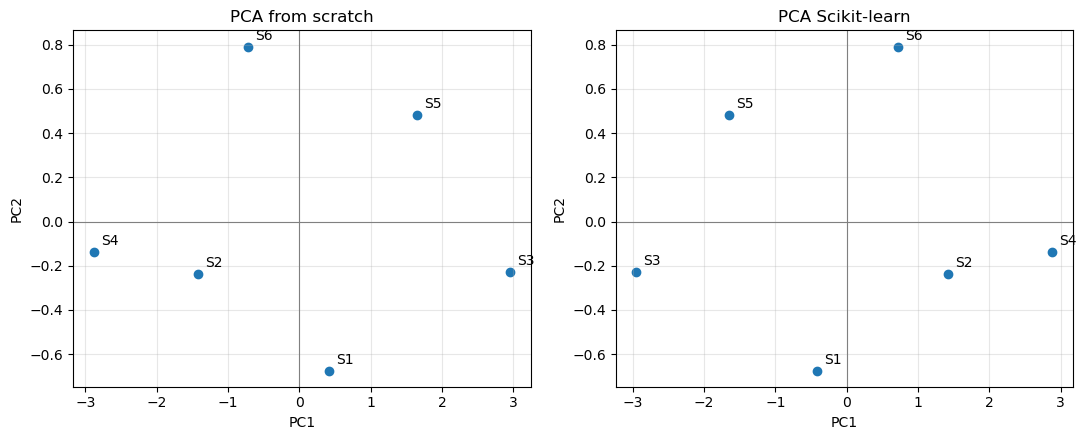

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, sc, title in zip(axes, [scores_scratch, scores_sk],
                         ["PCA from scratch", "PCA Scikit-learn"]):
    ax.scatter(sc[:, 0], sc[:, 1])
    for i, name in enumerate(df.index):
        ax.annotate(name, (sc[i, 0], sc[i, 1]),
                    textcoords="offset points", xytext=(5, 5))
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(title)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Explain the differences

In [37]:
for j in range(2):
    same = np.allclose(scores_scratch[:, j], scores_sk[:, j])   #identical signs?
    flipped = np.allclose(scores_scratch[:, j], -scores_sk[:, j])  #exact mirror?
    print(f"PC{j+1}: same sign = {same}, flipped sign = {flipped}")

PC1: same sign = False, flipped sign = True
PC2: same sign = True, flipped sign = False


In [36]:
#scratch
print(f"Variance retained by PC1+PC2: {cum_scratch[1]*100:.2f}%")
#sklearn
print(f"(sklearn) {pca2.explained_variance_ratio_.sum()*100:.2f}%")

Variance retained by PC1+PC2: 99.50%
(sklearn) 99.50%
